# AirAware: tomorrow's PM2.5 forecast for Kathmandu schools

**Track:** AI + Climate (suggested project 4.3.2, next-day air quality forecast)

**Who it is for:** school staff in Kathmandu deciding, the afternoon before, *"Should we hold outdoor PE and assembly tomorrow?"*

**What goes in / comes out:** today's PM2.5 at a monitoring station plus today's weather → tomorrow's daily-average PM2.5 (μg/m³), a warning above 35 μg/m³ and a plain-language precaution in English or Nepali.

> **This project is a prototype and is not medical advice.**

This notebook runs the whole pipeline: data → features → baselines → models → evaluation on an unseen test year → example forecasts. Every number below is computed in this notebook. Nothing is typed in by hand.

## 0. Setup
In Google Colab this cell downloads our code and data from GitHub and installs pinned package versions. Run locally, it just finds the project folder.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("AirAware"):
        !git clone -q https://github.com/Rokerpro/AirAware.git
    os.chdir("AirAware")
    !pip -q install -r ml/requirements.txt
else:
    while not os.path.exists("ml/src") and os.getcwd() != "/":
        os.chdir("..")
sys.path.insert(0, os.path.abspath("ml/src"))
print("project folder:", os.getcwd())

project folder: /home/rokermhr/Projects/AirAware


## 1. Data
* **OpenAQ** (openaq.org): daily-average PM2.5 from 6 Kathmandu monitoring stations. These are real measurements. Downloaded with `ml/src/fetch_data.py` (needs a free OpenAQ API key, which is *not* stored in this repo; the downloaded CSVs are included so this notebook runs without a key).
* **Open-Meteo historical weather** (open-meteo.com): daily temperature, humidity, wind, rain and pressure for Kathmandu.
* **CAMS via Open-Meteo air quality**: the global CAMS model's PM2.5 for Kathmandu. This is **model output, not a measurement**; we use it only as a second forecast to compare against.

Days where a station reported less than 75% of its hourly readings are dropped.

In [2]:
import pandas as pd
pm = pd.read_csv("ml/data/pm25_daily.csv", parse_dates=["date"])
cov = pm.groupby("station").agg(first_day=("date", "min"), last_day=("date", "max"),
                                days_with_data=("date", "nunique"), mean_pm25=("pm25", "mean"))
cov["first_day"] = cov.first_day.dt.date; cov["last_day"] = cov.last_day.dt.date
cov.round(1).sort_values("days_with_data", ascending=False)

,first_day,last_day,days_with_data,mean_pm25
station,,,,
Embassy Kathmandu,2017-03-03,2026-06-18,2803,43.7
"Dabali, Handigaun",2024-05-16,2026-10-19,737,42.1
KIAS,2025-05-01,2026-11-13,457,44.2
Lagankhel (SC-05),2025-10-03,2026-11-13,369,48.5
Shantichowk (SC-11),2025-10-09,2026-11-13,363,47.2
Gaushala Chowk (SC-01),2025-09-19,2026-11-13,324,58.3


Note: the US Embassy station has the long history (since 2017) but **stopped reporting in June 2026**. The other five stations started in 2024-2025, so they have little training data.

## 2. Features and the time split (no leakage)
For each station and day **D** we use only things known by the end of day D: PM2.5 today, yesterday and the 3-day average, today's weather, and the month. The target is PM2.5 on **D+1**.

We split **by time**, never randomly: everything before 1 Nov 2025 is training data; 1 Nov 2025 to 12 Nov 2026 (a full year, including winter smog and the spring burning season) is the **test** year the models never see.

In [3]:
from build_features import FEATURES, TEST_START
feat = pd.read_csv("ml/data/features.csv", parse_dates=["date"])
print("features:", FEATURES)
print("test starts:", TEST_START)
feat.pivot_table(index="station", columns="split", values="target_pm25", aggfunc="count", fill_value=0)

features: ['pm25_today', 'pm25_yesterday', 'pm25_mean3', 'temp_c', 'humidity_pct', 'wind_kmh', 'precip_mm', 'pressure_hpa', 'month']
test starts: 2025-11-01


split,test,train
station,,
"Dabali, Handigaun",322,289
Embassy Kathmandu,155,1923
Gaushala Chowk (SC-01),194,41
KIAS,292,125
Lagankhel (SC-05),295,16
Shantichowk (SC-11),221,8


## 3. Baselines
A model is only useful if it beats simple forecasts:
1. **Persistence**: "tomorrow will be the same as today" (required by the brief).
2. **CAMS**: the global air-quality model's value for tomorrow.

MAE (mean absolute error) = on average, how many μg/m³ the forecast is off by. Lower is better.

In [4]:
import baselines
baselines.main()

Test period 2025-11-01 to 2026-11-12, 1479 station-days
MAE in ug/m3, lower is better

               station    n  mae_persist  n_cams  mae_persist_c  mae_cams
     Dabali, Handigaun  322          7.1     322            7.1      10.7
     Embassy Kathmandu  155          7.8     155            7.8      14.1
Gaushala Chowk (SC-01)  194          8.4     194            8.4      23.0
                  KIAS  292          9.0     292            9.0      15.7
     Lagankhel (SC-05)  295          8.1     295            8.1      12.6
   Shantichowk (SC-11)  221          8.4     221            8.4      13.4
                   ALL 1479          8.1    1479            8.1      14.4 

  month    n  mae_persist  n_cams  mae_persist_c  mae_cams
2025-11  114          7.0     114            7.0      16.3
2025-12  157          7.6     157            7.6      17.5
2026-01  143         11.8     143           11.8      14.7
2026-02  114          8.6     114            8.6      16.5
2026-03  142         11.

Persistence is hard to beat (MAE about 8 μg/m³) because Kathmandu's air changes slowly from day to day. CAMS is much worse here and **too low by about 7.5 μg/m³ on average**: a global model misses local valley pollution.

## 4. Models
One model is shared by all stations (most stations have too few training days for their own model).
* **Linear regression:** adds up the features, each multiplied by a learned weight.
* **Random Forest (v1):** averages 300 decision trees. It can learn non-linear patterns.
* **Random Forest (v2, our improvement):** the same forest, but it learns tomorrow's **change** from today, then we add today back. A forest averages training examples, so predicting levels pulls extreme days toward the middle; predicting the change keeps persistence as the starting point.

Settings are chosen on the **last 12 months of the training period** (Nov 2024-Oct 2025), never on the test year.

In [5]:
import train
train.main()

fit rows 1891 (2017-03-11..2024-10-31), val rows 511 (2024-11-01..2025-10-31)



               model                                      params  val_mae
         persistence                                                 6.73
   linear_regression                                                 6.81
       random_forest     {"max_depth": 6, "min_samples_leaf": 5}     6.60
       random_forest    {"max_depth": 6, "min_samples_leaf": 20}     6.61
       random_forest    {"max_depth": 10, "min_samples_leaf": 5}     6.59
       random_forest   {"max_depth": 10, "min_samples_leaf": 20}     6.60
       random_forest  {"max_depth": null, "min_samples_leaf": 5}     6.62
       random_forest {"max_depth": null, "min_samples_leaf": 20}     6.60
random_forest_change     {"max_depth": 6, "min_samples_leaf": 5}     6.42
random_forest_change    {"max_depth": 6, "min_samples_leaf": 20}     6.35
random_forest_change    {"max_depth": 10, "min_samples_leaf": 5}     6.51
random_forest_change   {"max_depth": 10, "min_samples_leaf": 20}     6.37
random_forest_change  {"max_depth": nu


linear regression coefficients (ug/m3 change per unit of each feature):
pm25_today        0.611
pm25_yesterday   -0.044
pm25_mean3        0.116
temp_c           -0.916
humidity_pct     -0.418
wind_kmh          0.407
precip_mm        -0.042
pressure_hpa     -0.395
month            -0.053

random forest feature importance (share of error reduction):
pm25_today        0.812
pm25_mean3        0.092
precip_mm         0.031
humidity_pct      0.015
temp_c            0.015
pm25_yesterday    0.013
pressure_hpa      0.009
wind_kmh          0.009
month             0.004

Saved models to /home/rokermhr/Projects/AirAware/ml/models


In the forest, today's PM2.5 matters most by far. Weather adds a little.

## 5. Results on the unseen test year

In [6]:
import evaluate
evaluate.main()

TEST 2025-11-01..2026-11-12, 1479 station-days

            forecast   mae  bias_pred_minus_actual  median_abs_error
         persistence  8.10                   -0.16              5.10
                cams 14.45                   -7.45              9.92
   linear_regression  8.23                   -3.06              5.68
       random_forest  7.89                   -1.52              5.24
random_forest_change  7.79                   -1.53              4.92 

               station    n  mean_pm25  persistence  cams  linear_regression  random_forest  random_forest_change
     Dabali, Handigaun  322       48.4         7.06 10.68               6.72           6.42                  6.41
     Embassy Kathmandu  155       50.0         7.76 14.15               8.30           8.11                  7.79
Gaushala Chowk (SC-01)  194       59.0         8.45 22.97              10.11           8.90                  9.00
                  KIAS  292       52.6         8.98 15.70               8.94    

### Charts

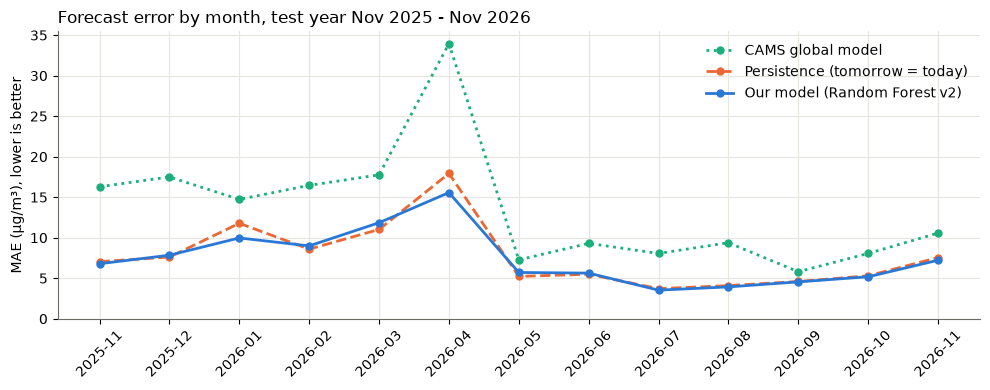

In [7]:
import matplotlib.pyplot as plt
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#1f1f1e", "#6b6a64"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "font.size": 10})
mo = pd.read_csv("ml/experiments/test_mae_by_month.csv")
mo = mo[mo.month != "ALL"]
fig, ax = plt.subplots(figsize=(10, 4))
for col, color, label, style in [("cams", AQUA, "CAMS global model", ":"),
                                 ("persistence", ORANGE, "Persistence (tomorrow = today)", "--"),
                                 ("random_forest_change", BLUE, "Our model (Random Forest v2)", "-")]:
    ax.plot(mo.month, mo[col], style, color=color, lw=2, marker="o", ms=5, label=label)
ax.set_ylabel("MAE (μg/m³), lower is better"); ax.set_ylim(bottom=0)
ax.set_title("Forecast error by month, test year Nov 2025 - Nov 2026", loc="left")
ax.legend(frameon=False); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

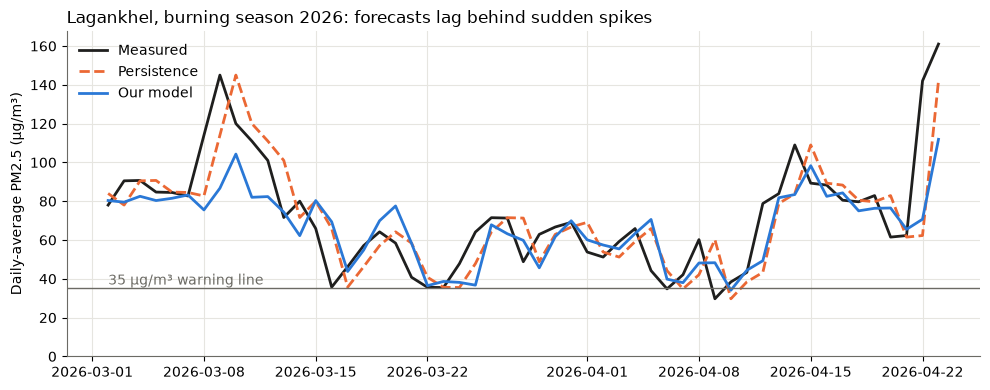

In [8]:
pred = pd.read_csv("ml/experiments/test_predictions.csv", parse_dates=["date"])
p = pred[(pred.station == "Lagankhel (SC-05)") & (pred.date.between("2026-03-01", "2026-05-15"))].copy()
p["forecast_for"] = p.date + pd.Timedelta(days=1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(p.forecast_for, p.target_pm25, color=INK, lw=2, label="Measured")
ax.plot(p.forecast_for, p.persistence, "--", color=ORANGE, lw=2, label="Persistence")
ax.plot(p.forecast_for, p.random_forest_change, color=BLUE, lw=2, label="Our model")
ax.axhline(35, color=MUTED, lw=1); ax.text(p.forecast_for.min(), 37, "35 μg/m³ warning line", color=MUTED)
ax.set_ylabel("Daily-average PM2.5 (μg/m³)"); ax.set_ylim(bottom=0)
ax.set_title("Lagankhel, burning season 2026: forecasts lag behind sudden spikes", loc="left")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 6. Where it fails
* **Sudden spikes in the burning season (March-April).** On 21-22 April 2026 PM2.5 jumped from about 60-130 to about 140-180 μg/m³ at several stations; the next drop on 24 April was also missed. Our features only describe *today*, so the model cannot see a fire or a change in wind coming. Every forecast (ours, persistence and CAMS) misses these days.
* **High-pollution months have the largest errors** (Jan, Mar, Apr: MAE 10-16 μg/m³ versus 4-5 in the monsoon).
* **The gain over persistence is small.** The weekly block bootstrap above shows the 95% interval for the improvement includes zero, so we cannot claim the model is reliably better than "tomorrow = today". It is better on most stations and most months of this test year.
* **Stations move together** (daily correlation 0.89-0.99), so the neighbourhood alert cards usually agree; Kathmandu's pollution is mostly valley-wide.
* **35 μg/m³ is exceeded on 68% of test days** (every day Dec-Feb), so at that line the warning is almost always on. We therefore also report a higher line, 55.5 μg/m³ (AQI "Unhealthy" for everyone), which gives schools a clearer "move PE indoors" signal.

## 7. Try a forecast
`predict.forecast(station_id, date, language)` is what the demo app calls. It loads the saved model; it never retrains.

In [9]:
import json, predict
print(json.dumps(predict.list_stations(), indent=1))
example = predict.forecast("5509788", "2026-04-20", language="en")
print(json.dumps(example, indent=1, ensure_ascii=False))

{
 "stations": [
  {
   "station_id": "2848864",
   "station_name": "Dabali, Handigaun",
   "first_date": "2024-05-18",
   "last_date": "2026-10-18"
  },
  {
   "station_id": "3459",
   "station_name": "Embassy Kathmandu",
   "first_date": "2017-03-11",
   "last_date": "2026-06-09"
  },
  {
   "station_id": "4121681",
   "station_name": "KIAS",
   "first_date": "2025-05-04",
   "last_date": "2026-11-13"
  },
  {
   "station_id": "5506835",
   "station_name": "Gaushala Chowk (SC-01)",
   "first_date": "2025-09-21",
   "last_date": "2026-11-13"
  },
  {
   "station_id": "5509788",
   "station_name": "Lagankhel (SC-05)",
   "first_date": "2025-10-05",
   "last_date": "2026-11-13"
  },
  {
   "station_id": "6070692",
   "station_name": "Shantichowk (SC-11)",
   "first_date": "2025-10-12",
   "last_date": "2026-11-13"
  }
 ]
}
{
 "station_id": "5509788",
 "station_name": "Lagankhel (SC-05)",
 "forecast_for": "2026-04-21",
 "predicted_pm25": 65.5,
 "aqi_band": "Unhealthy",
 "warning": true,


In [10]:
print(json.dumps(predict.forecast("4121681", "2026-11-13", language="ne"), indent=1, ensure_ascii=False))

{
 "station_id": "4121681",
 "station_name": "KIAS",
 "forecast_for": "2026-11-14",
 "predicted_pm25": 60.2,
 "aqi_band": "Unhealthy",
 "warning": true,
 "alert_level": "high",
 "baselines": {
  "persistence_pm25": 58.8,
  "cams_pm25": 90.1
 },
 "actual_pm25": null,
 "precaution": "भोलि हावा सबैका लागि अस्वस्थ हुने अनुमान छ। खेलकुद र प्रार्थना सभा भित्र सार्नुहोस्।",
 "disclaimer": "प्रोटोटाइप मात्र, स्वास्थ्य सल्लाह होइन।",
 "model_version": "random_forest_v2"
}


## Sources
* OpenAQ API v3, https://openaq.org (PM2.5 monitor data; see each station's provider on OpenAQ for licence terms)
* Open-Meteo Historical Weather API, https://open-meteo.com (CC BY 4.0)
* Open-Meteo Air Quality API (CAMS, Copernicus Atmosphere Monitoring Service), https://open-meteo.com/en/docs/air-quality-api
* US EPA PM2.5 AQI breakpoints (2024 revision), https://www.airnow.gov/aqi/aqi-basics/
* Libraries: pandas, scikit-learn, matplotlib, joblib
* AI tools: Claude Code (Anthropic) helped write and review code; the team checked and can explain every part.

**This project is a prototype and is not medical advice.**